<a href="https://colab.research.google.com/github/amit809070/Machine-Learning-Lab-Assignments---M-tech-CSE/blob/main/Experiment%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 3-Lab Experiment 3: Gaussian Mixture Models and EM Algorithm
Objective: To implement the Expectation-Maximization (EM) algorithm for Gaussian Mixture Models and perform soft clustering.
Software / Tools Required:
•	Python 3.x, NumPy, Matplotlib, Scikit-learn
Procedure:
•	Generate a synthetic 2D dataset with multiple Gaussian clusters.
•	Implement the E-step (compute responsibilities) and M-step (update parameters) of the EM algorithm from scratch.
•	Visualize the clusters and Gaussian ellipses after selected iterations.
•	Compare the results with sklearn.mixture.GaussianMixture.
Expected Outcome: Understanding of soft clustering, mixture models, and the EM algorithm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

print("All libraries imported successfully!")

All libraries imported successfully!


Dataset Shape: (450, 2)


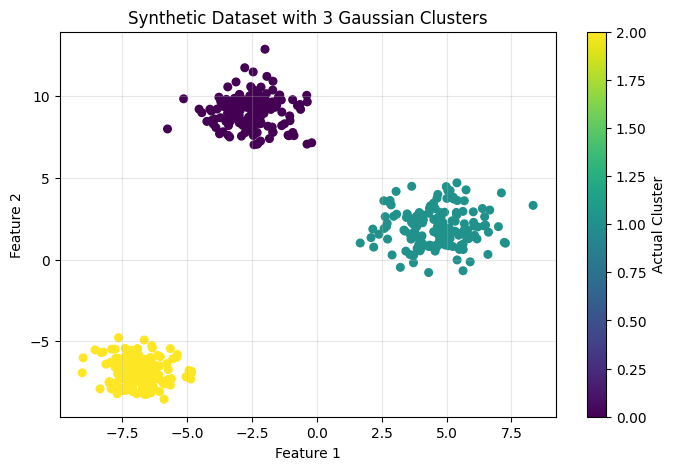

In [2]:
# Generate dataset with 3 Gaussian clusters

X, y_true = make_blobs(
    n_samples=450,
    centers=3,
    n_features=2,
    cluster_std=[1.0, 1.2, 0.8],
    random_state=42
)

print("Dataset Shape:", X.shape)

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap='viridis', s=30)

plt.title("Synthetic Dataset with 3 Gaussian Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label="Actual Cluster")
plt.grid(alpha=0.3)
plt.show()

In [3]:
def gaussian_pdf(X, mean, covariance):

    n_features = X.shape[1]

    diff = X - mean

    inverse = np.linalg.inv(covariance)

    determinant = np.linalg.det(covariance)

    exponent = np.einsum(
        'ij,jk,ik->i',
        diff,
        inverse,
        diff
    )

    denominator = np.sqrt(
        ((2 * np.pi) ** n_features) * determinant
    )

    return np.exp(-0.5 * exponent) / denominator


print("Gaussian PDF function created successfully!")

Gaussian PDF function created successfully!


In [4]:
def initialize_parameters(X, K):

    n_samples, n_features = X.shape

    np.random.seed(42)

    # Randomly select initial means
    random_indices = np.random.choice(
        n_samples, K, replace=False
    )

    means = X[random_indices]

    # Initialize covariance matrices
    covariances = np.array([
        np.cov(X.T) + 1e-6 * np.eye(n_features)
        for _ in range(K)
    ])

    # Equal mixing weights
    weights = np.ones(K) / K

    return means, covariances, weights


K = 3

means, covariances, weights = initialize_parameters(X, K)

print("Initial Means:\n", means)
print("\nInitial Weights:\n", weights)

Initial Means:
 [[ 2.79894183  3.50638187]
 [-7.74447785 -6.38736111]
 [ 6.61384009  1.67432644]]

Initial Weights:
 [0.33333333 0.33333333 0.33333333]


In [5]:
def E_step(X, means, covariances, weights):

    n_samples = X.shape[0]
    K = len(weights)

    responsibilities = np.zeros((n_samples, K))

    for k in range(K):

        responsibilities[:, k] = (
            weights[k] *
            gaussian_pdf(X, means[k], covariances[k])
        )

    # Normalize probabilities
    responsibilities = responsibilities / (
        responsibilities.sum(axis=1, keepdims=True) + 1e-12
    )

    return responsibilities


responsibilities = E_step(
    X, means, covariances, weights
)

print("Responsibilities Shape:", responsibilities.shape)
print("\nFirst 5 Samples:\n", responsibilities[:5])

Responsibilities Shape: (450, 3)

First 5 Samples:
 [[0.74207794 0.18638677 0.07153528]
 [0.53097687 0.03339822 0.43562491]
 [0.39876045 0.01366318 0.58757637]
 [0.46790822 0.02189563 0.51019615]
 [0.51523911 0.03078903 0.45397186]]


In [6]:
def M_step(X, responsibilities):

    n_samples, n_features = X.shape
    K = responsibilities.shape[1]

    Nk = responsibilities.sum(axis=0) + 1e-12

    # Update means
    means = (responsibilities.T @ X) / Nk[:, None]

    # Update covariance matrices
    covariances = []

    for k in range(K):

        diff = X - means[k]

        covariance = (
            (responsibilities[:, k, None] * diff).T @ diff
        ) / Nk[k]

        covariance += 1e-6 * np.eye(n_features)

        covariances.append(covariance)

    covariances = np.array(covariances)

    # Update mixing coefficients
    weights = Nk / n_samples

    return means, covariances, weights


means, covariances, weights = M_step(
    X, responsibilities
)

print("Updated Means:\n", means)
print("\nUpdated Weights:\n", weights)

Updated Means:
 [[-0.17742074  5.26733546]
 [-5.84322906 -3.45172556]
 [ 3.57544001  2.4032579 ]]

Updated Weights:
 [0.42159431 0.37927745 0.19912824]


In [7]:
def EM_algorithm(X, K=3, max_iter=100, tolerance=1e-5):

    means, covariances, weights = initialize_parameters(X, K)

    log_likelihoods = []

    for iteration in range(max_iter):

        # E-Step
        responsibilities = E_step(
            X, means, covariances, weights
        )

        # M-Step
        means, covariances, weights = M_step(
            X, responsibilities
        )

        # Calculate log likelihood
        likelihood = np.zeros(len(X))

        for k in range(K):
            likelihood += (
                weights[k] *
                gaussian_pdf(X, means[k], covariances[k])
            )

        log_likelihood = np.sum(
            np.log(likelihood + 1e-12)
        )

        log_likelihoods.append(log_likelihood)

        if iteration > 0:

            if abs(
                log_likelihoods[-1] - log_likelihoods[-2]
            ) < tolerance:

                print("Converged at iteration:", iteration + 1)
                break

    return means, covariances, weights, responsibilities, log_likelihoods


means, covariances, weights, responsibilities, log_likelihoods = EM_algorithm(
    X, K=3
)

print("\nFinal Means:\n", means)
print("\nFinal Weights:\n", weights)
print("\nFinal Log Likelihood:", log_likelihoods[-1])

Converged at iteration: 8

Final Means:
 [[-2.55001056  9.03069552]
 [-6.8591003  -6.78422046]
 [ 4.67201026  1.92374538]]

Final Weights:
 [0.33333333 0.33333333 0.33333333]

Final Log Likelihood: -1738.0981795697871


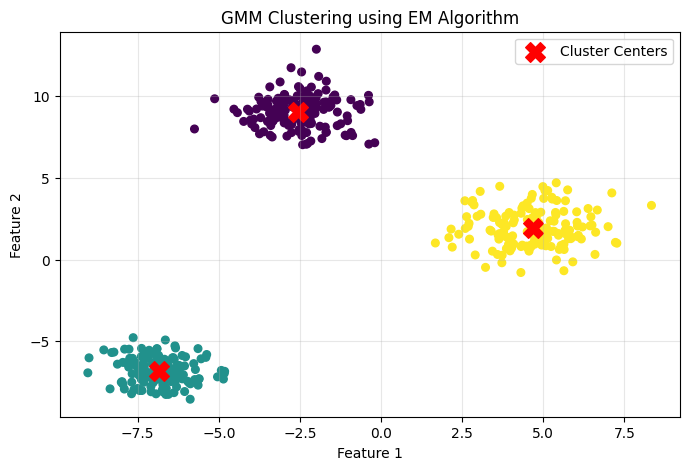

In [8]:
# Assign cluster based on maximum responsibility
labels = np.argmax(responsibilities, axis=1)

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap='viridis',
    s=30
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Cluster Centers'
)

plt.title("GMM Clustering using EM Algorithm")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

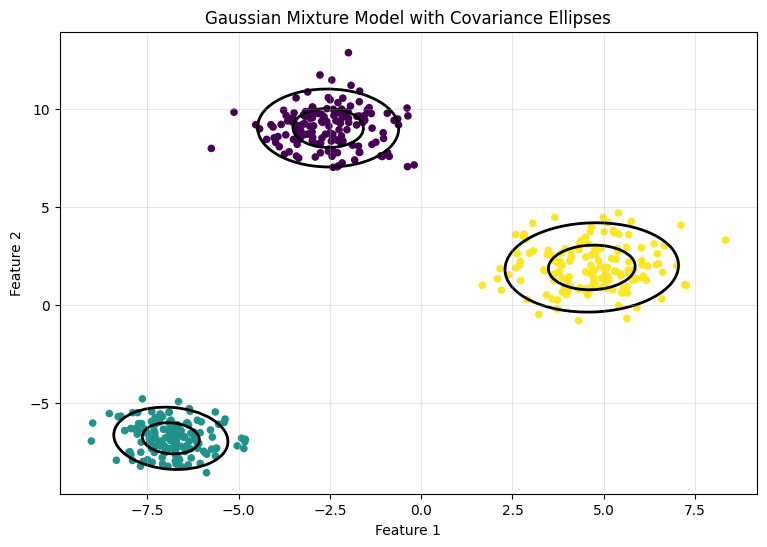

In [9]:
from matplotlib.patches import Ellipse

def plot_gaussian_ellipses(X, means, covariances, labels):

    plt.figure(figsize=(9, 6))

    plt.scatter(
        X[:, 0], X[:, 1],
        c=labels, cmap='viridis', s=20
    )

    ax = plt.gca()

    for k in range(len(means)):

        eigenvalues, eigenvectors = np.linalg.eigh(
            covariances[k]
        )

        order = eigenvalues.argsort()[::-1]

        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        angle = np.degrees(
            np.arctan2(
                eigenvectors[1, 0],
                eigenvectors[0, 0]
            )
        )

        for scale in [1, 2]:

            ellipse = Ellipse(
                xy=means[k],
                width=2 * scale * np.sqrt(eigenvalues[0]),
                height=2 * scale * np.sqrt(eigenvalues[1]),
                angle=angle,
                fill=False,
                linewidth=2
            )

            ax.add_patch(ellipse)

    plt.title("Gaussian Mixture Model with Covariance Ellipses")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.grid(alpha=0.3)
    plt.show()


plot_gaussian_ellipses(
    X, means, covariances, labels
)

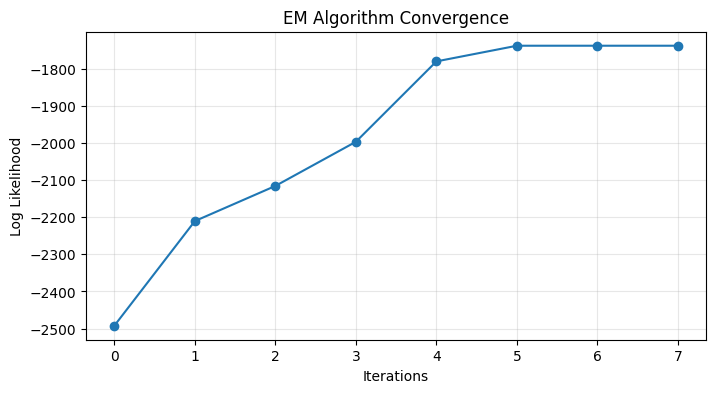

In [10]:
plt.figure(figsize=(8, 4))

plt.plot(
    log_likelihoods,
    marker='o'
)

plt.title("EM Algorithm Convergence")
plt.xlabel("Iterations")
plt.ylabel("Log Likelihood")

plt.grid(alpha=0.3)
plt.show()

In [11]:
# Create sklearn GMM model

gmm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    random_state=42
)

gmm.fit(X)

sklearn_labels = gmm.predict(X)

print("Scikit-learn GMM Results")

print("\nMeans:\n", gmm.means_)

print("\nWeights:\n", gmm.weights_)

print("\nConverged:", gmm.converged_)

print("\nNumber of Iterations:", gmm.n_iter_)

Scikit-learn GMM Results

Means:
 [[-2.55001056  9.03069552]
 [-6.8591003  -6.78422046]
 [ 4.67201026  1.92374538]]

Weights:
 [0.33333333 0.33333333 0.33333333]

Converged: True

Number of Iterations: 2


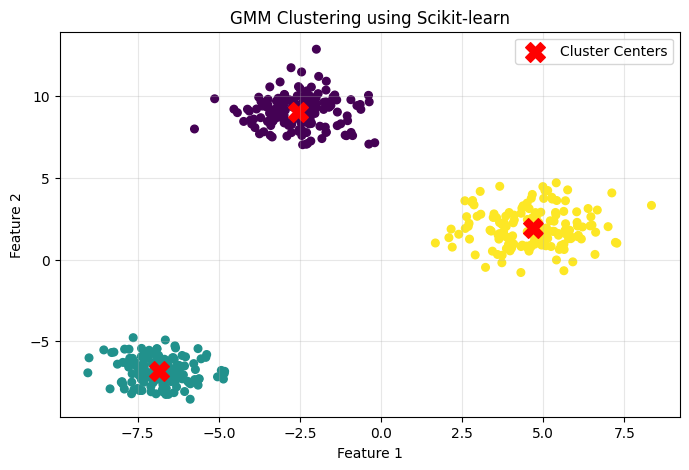

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=sklearn_labels,
    cmap='viridis',
    s=30
)

plt.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Cluster Centers'
)

plt.title("GMM Clustering using Scikit-learn")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
# Predict probability of each sample belonging to each cluster

probabilities = gmm.predict_proba(X)

print("First 10 Samples Responsibilities:\n")

print(np.round(probabilities[:10], 3))

print("\nShape:", probabilities.shape)

First 10 Samples Responsibilities:

[[1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]]

Shape: (450, 3)
